In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/waqi786/impact-of-virtual-reality-on-education/Virtual_Reality_in_Education_Impact.csv


In [3]:
!pip install kaleido==0.1.*

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.6/74.6 MB 21.5 MB/s eta 0:00:00:00:0100:01


In [4]:
df = pd.read_csv('/kaggle/input/datasets/waqi786/impact-of-virtual-reality-on-education/Virtual_Reality_in_Education_Impact.csv')
df=df.set_index('Student_ID')
df.head()

,Age,Gender,Grade_Level,Field_of_Study,Usage_of_VR_in_Education,Hours_of_VR_Usage_Per_Week,Engagement_Level,Improvement_in_Learning_Outcomes,Subject,Instructor_VR_Proficiency,Perceived_Effectiveness_of_VR,Access_to_VR_Equipment,Impact_on_Creativity,Stress_Level_with_VR_Usage,Collaboration_with_Peers_via_VR,Feedback_from_Educators_on_VR,Interest_in_Continuing_VR_Based_Learning,Region,School_Support_for_VR_in_Curriculum
Student_ID,,,,,,,,,,,,,,,,,,,
STUD0001,13,Non-binary,Postgraduate,Science,No,6,1,Yes,Computer Science,Intermediate,3,Yes,5,High,No,Neutral,No,South America,No
STUD0002,16,Non-binary,Undergraduate,Medicine,No,6,1,Yes,Math,Beginner,2,Yes,3,Low,Yes,Positive,No,Oceania,No
STUD0003,15,Prefer not to say,High School,Science,No,4,5,Yes,Art,Advanced,5,Yes,2,Low,Yes,Neutral,Yes,Oceania,No
STUD0004,24,Female,Postgraduate,Engineering,Yes,2,4,No,Economics,Beginner,5,No,3,High,No,Neutral,No,Europe,Yes
STUD0005,22,Non-binary,Undergraduate,Arts,Yes,10,3,No,Art,Beginner,4,Yes,1,Medium,No,Negative,Yes,North America,Yes


In [5]:
df.shape

(5000, 19)

In [6]:
df.isnull().sum()

Age                                         0
Gender                                      0
Grade_Level                                 0
Field_of_Study                              0
Usage_of_VR_in_Education                    0
Hours_of_VR_Usage_Per_Week                  0
Engagement_Level                            0
Improvement_in_Learning_Outcomes            0
Subject                                     0
Instructor_VR_Proficiency                   0
Perceived_Effectiveness_of_VR               0
Access_to_VR_Equipment                      0
Impact_on_Creativity                        0
Stress_Level_with_VR_Usage                  0
Collaboration_with_Peers_via_VR             0
Feedback_from_Educators_on_VR               0
Interest_in_Continuing_VR_Based_Learning    0
Region                                      0
School_Support_for_VR_in_Curriculum         0
dtype: int64

In [7]:
df = df[df['Region']=='Asia']
df = df[df['Grade_Level']!='High School']
df = df[df['Gender'].isin(['Male','Female'])]

In [ ]:
df.info()

In [ ]:
df.describe().T

In [ ]:
df.describe(include='object').T

In [9]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px

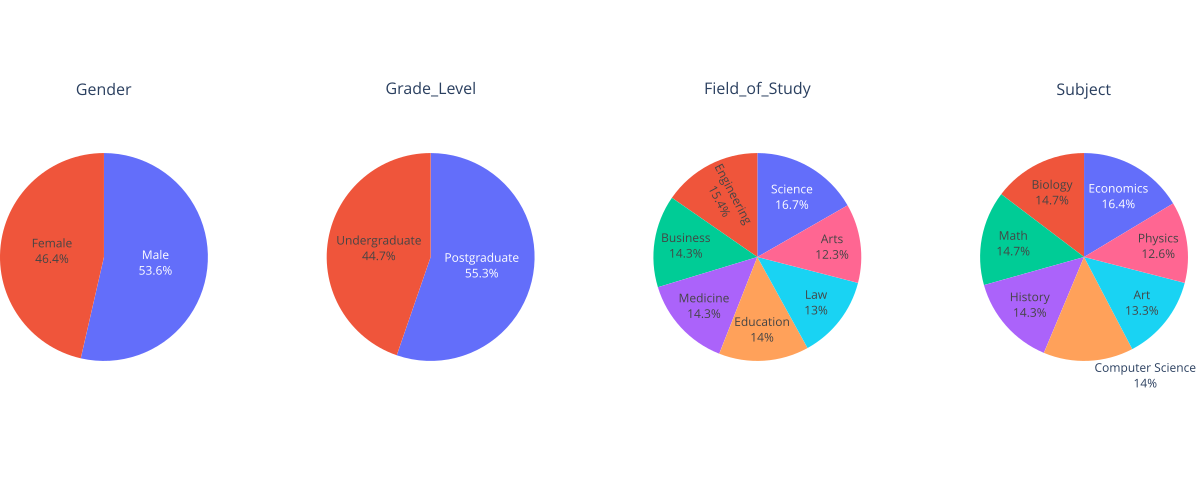

In [107]:
cols = ['Gender','Grade_Level','Field_of_Study','Subject']
fig = make_subplots(rows=1,cols=4,specs=[[{'type':'pie'} for i in range(4)]],subplot_titles=cols,horizontal_spacing=0.1)
for idx,col in enumerate(cols):
    vcdf = df[col].value_counts().reset_index()
    fig.add_trace(go.Pie(labels=vcdf[col],values=vcdf['count'],marker=dict(colors=px.colors.qualitative.Plotly),showlegend=False,textinfo='percent+label'),row=1,col=idx%4+1) 
fig.update_layout(width=1200,margin=dict(l=0,r=0,b=0)) 
fig.show('svg')

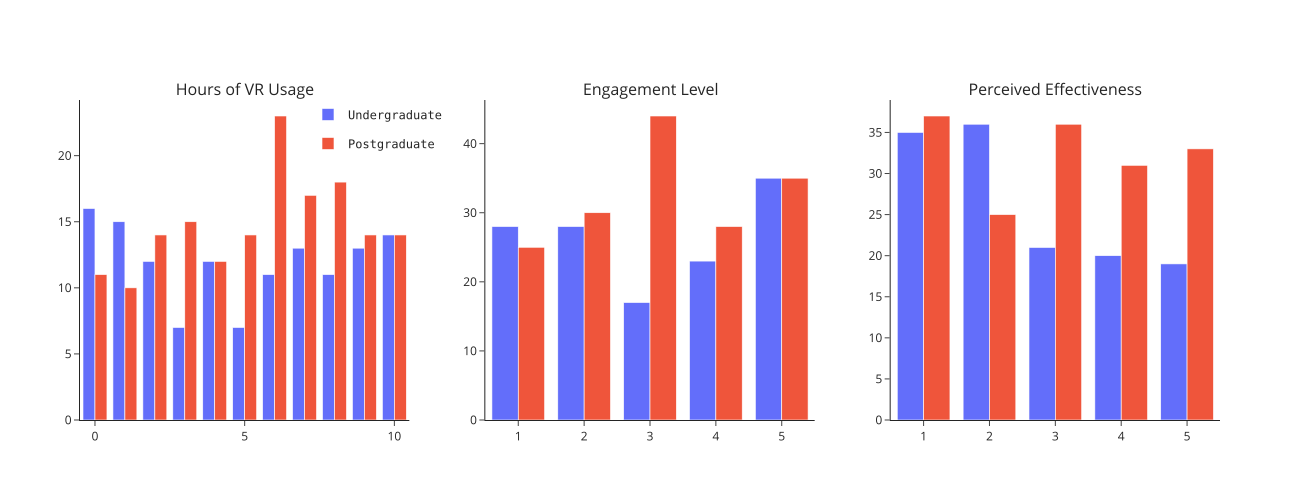

In [152]:
fig = make_subplots(rows=1,cols=3,subplot_titles=['Hours of VR Usage','Engagement Level','Perceived Effectiveness'])
fig1 = px.histogram(df,x='Hours_of_VR_Usage_Per_Week',color='Grade_Level',barmode='group') 
for trace in fig1.data:
    fig.add_trace(trace,row=1,col=1) 
fig2 = px.histogram(df,x='Engagement_Level',color='Grade_Level',barmode='group')
for trace in fig2.data:
    fig.add_trace(trace,row=1,col=2)
fig3 = px.histogram(df,x='Perceived_Effectiveness_of_VR',color='Grade_Level',barmode='group')
for trace in fig3.data:
    fig.add_trace(trace,row=1,col=3)
fig.update_traces(showlegend=False,row=1,col=2) 
fig.update_traces(showlegend=False,row=1,col=3) 
fig.update_layout({'template':'simple_white','width':1300,'legend':{'x':0.2,'font':{'family':'Open-Sans,verdana,monospace'}}})
fig.show('svg')

In [16]:
# vcdf = df.groupby(['Improvement_in_Learning_Outcomes','Subject']).value_counts().reset_index()
# fig = px.pie(vcdf,names='Improvement_in_Learning_Outcomes',values='count',facet_col='Subject',facet_col_wrap=4) 
# fig.update_layout({'width':1200,'margin':{'l':0,'r':0,'b':0},'legend':{"orientation":'h','xanchor':'center','x':0.5,'y':1.07,'font':{'size':14}}})
# fig.for_each_annotation(lambda a:a.update(text=a.text.split('=')[-1],font=dict(size=14))) 
# fig.show('svg')

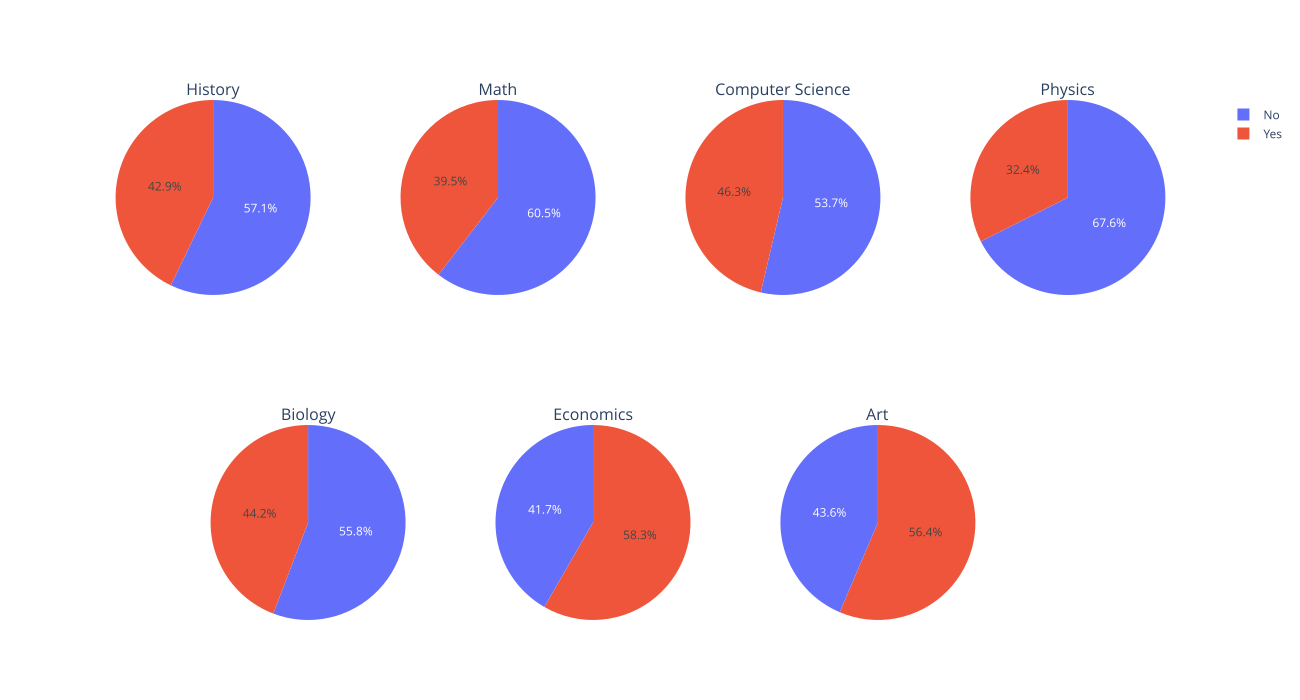

In [15]:
subs = df['Subject'].unique()
fig = make_subplots(rows=2,cols=12,subplot_titles=subs,specs=[[{"type":"pie","colspan":3},None,None,{"type":"pie","colspan":3},None,None,{"type":"pie","colspan":3},None,None,{"type":"pie","colspan":3},None,None],[None, {"l":0,"colspan": 3,"type":"pie"}, None, None, {"colspan": 3,"type":"pie"}, None, None, {"colspan": 3,"type":"pie"}, None, None, None, None]])
for i in range(4):
    vcdf = df.loc[df['Subject']==subs[i]]['Improvement_in_Learning_Outcomes'].value_counts().reset_index()
    fig.add_trace(go.Pie(labels=vcdf['Improvement_in_Learning_Outcomes'],values=vcdf['count']),row=1,col=i*3+1) 
idx=4
for i in [2,5,8]: 
    vcdf = df.loc[df['Subject']==subs[idx]]['Improvement_in_Learning_Outcomes'].value_counts().reset_index()
    fig.add_trace(go.Pie(labels=vcdf['Improvement_in_Learning_Outcomes'],values=vcdf['count']),row=2,col=i)
    idx = idx+1
fig.update_layout({'width':1300,'height':700})
fig.show('svg') 

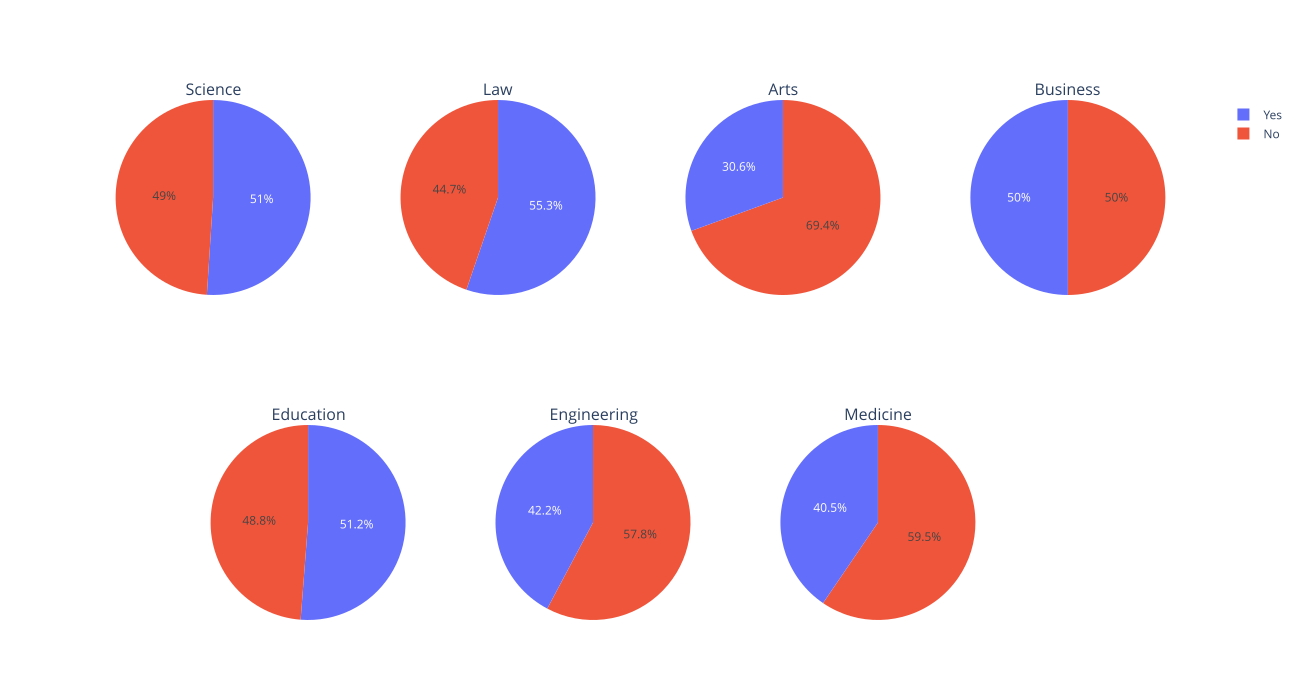

In [18]:
subs = df['Field_of_Study'].unique()
fig = make_subplots(rows=2,cols=12,subplot_titles=subs,specs=[[{"type":"pie","colspan":3},None,None,{"type":"pie","colspan":3},None,None,{"type":"pie","colspan":3},None,None,{"type":"pie","colspan":3},None,None],[None, {"l":0,"colspan": 3,"type":"pie"}, None, None, {"colspan": 3,"type":"pie"}, None, None, {"colspan": 3,"type":"pie"}, None, None, None, None]])
for i in range(4):
    vcdf = df.loc[df['Field_of_Study']==subs[i]]['Improvement_in_Learning_Outcomes'].value_counts().reset_index()
    fig.add_trace(go.Pie(labels=vcdf['Improvement_in_Learning_Outcomes'],values=vcdf['count']),row=1,col=i*3+1) 
idx=4
for i in [2,5,8]: 
    vcdf = df.loc[df['Field_of_Study']==subs[idx]]['Improvement_in_Learning_Outcomes'].value_counts().reset_index()
    fig.add_trace(go.Pie(labels=vcdf['Improvement_in_Learning_Outcomes'],values=vcdf['count']),row=2,col=i)
    idx = idx+1
fig.update_layout({'width':1300,'height':700})
fig.show('svg') 

### Instructor's Perceptions about VR

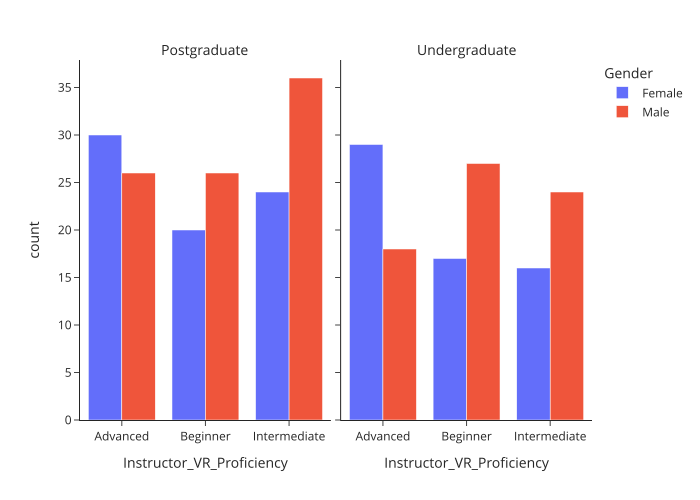

In [27]:
vcdf = df.groupby(['Instructor_VR_Proficiency','Grade_Level','Gender'])['Instructor_VR_Proficiency'].value_counts().reset_index()
fig = px.bar(vcdf,x='Instructor_VR_Proficiency',facet_col='Grade_Level',color='Gender',y='count',barmode='group') 
fig.update_layout(template='simple_white')
fig.for_each_annotation(lambda a:a.update(text=a.text.split('=')[-1],font=dict(size=14))) 
fig.show('svg')

In [108]:
for col in df.select_dtypes('object').columns:
    if 'Yes' in df[col].unique():
        df[col] = df[col].map({'Yes':1,'No':0}).astype(int)

In [112]:
for col in df.select_dtypes('object').columns:
    print(col,df[col].unique())

Gender ['Male' 'Female']
Grade_Level ['Undergraduate' 'Postgraduate']
Field_of_Study ['Science' 'Law' 'Arts' 'Business' 'Education' 'Engineering' 'Medicine']
Subject ['History' 'Math' 'Computer Science' 'Physics' 'Biology' 'Economics' 'Art']
Instructor_VR_Proficiency ['Advanced' 'Beginner' 'Intermediate']
Stress_Level_with_VR_Usage ['High' 'Low' 'Medium']
Feedback_from_Educators_on_VR ['Neutral' 'Negative' 'Positive']
Region ['Asia']


In [124]:
if 'High' in df['Stress_Level_with_VR_Usage'].unique():
    df['Stress_Level_with_VR_Usage'] = df['Stress_Level_with_VR_Usage'].map({'High':2,'Medium':1,'Low':0}).astype(int)
if 'Neutral' in df['Feedback_from_Educators_on_VR'].unique():
    df['Feedback_from_Educators_on_VR'] = df['Feedback_from_Educators_on_VR'].map({'Negative':-1,'Positive':1,'Neutral':0}).astype(int)
if 'Advanced' in df['Instructor_VR_Proficiency'].unique():
    df['Instructor_VR_Proficiency'] = df['Instructor_VR_Proficiency'].map({'Advanced':3,'Intermediate':2,'Beginner':1}).astype(int)

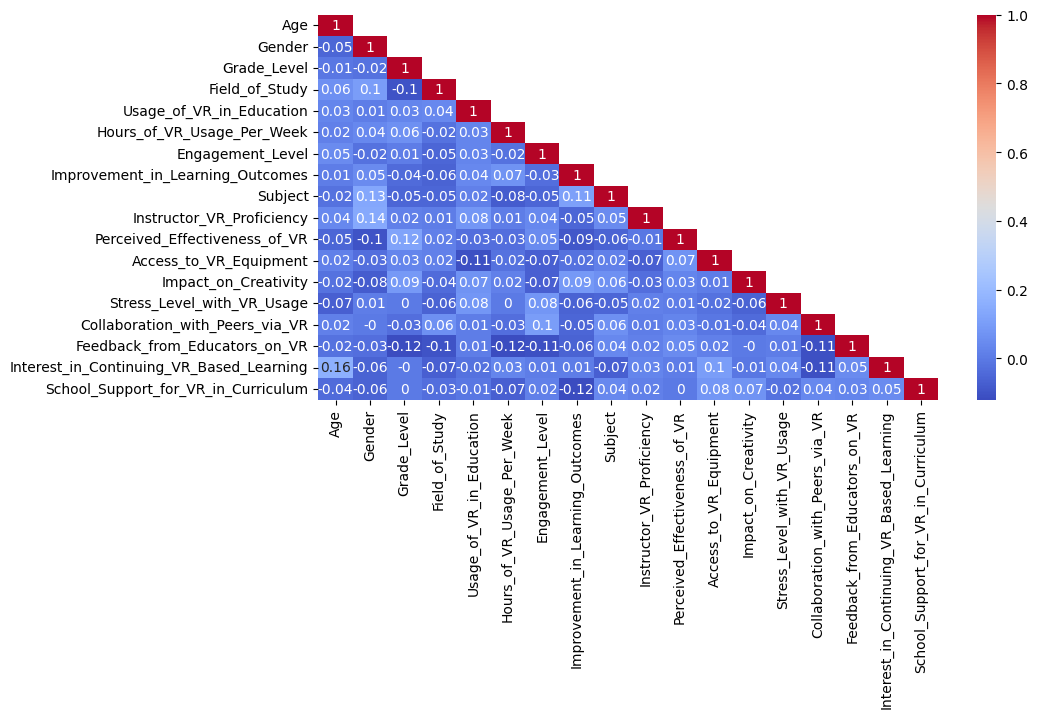

In [225]:
import seaborn as sns
import matplotlib.pyplot as plt
corr_df = df.select_dtypes(int).corr(method='spearman').round(2)
mask = np.triu(np.ones_like(corr_df))
np.fill_diagonal(mask,0)
plt.figure(figsize=(10,5))
sns.heatmap(corr_df,mask=mask,annot=True,cmap='coolwarm')
plt.show()

### Modelling as Logistic Regression
##### Target Variable: Improvement in Learning Outcomes


In [154]:
for col in ['Gender','Grade_Level','Field_of_Study','Subject']:
    mapper = {}
    for idx,val in enumerate(df[col].unique()):
        mapper[val]=idx
    df[col]=df[col].map(mapper)

In [210]:
X = df.drop(columns=['Region','Improvement_in_Learning_Outcomes'])
y = df['Improvement_in_Learning_Outcomes'].values

In [211]:
from sklearn.preprocessing import MinMaxScaler
X = MinMaxScaler().fit_transform(X)

In [212]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

In [213]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train,y_train)

LogisticRegression()

In [214]:
from sklearn.metrics import accuracy_score
y_pred = lr.predict(X_test)
accuracy_score(y_test,y_pred)

0.576271186440678

In [218]:
coeffs = lr.coef_[0]
odds = np.exp(coeffs)
pd.DataFrame({'Feature':df.drop(columns=['Region','Improvement_in_Learning_Outcomes']).columns,'Coefficient':coeffs,'Odds Ratio':odds}).sort_values(by='Coefficient',ascending=False).round(3)

,Feature,Coefficient,Odds Ratio
5,Hours_of_VR_Usage_Per_Week,0.636,1.889
11,Impact_on_Creativity,0.393,1.481
7,Subject,0.391,1.478
15,Interest_in_Continuing_VR_Based_Learning,0.202,1.224
10,Access_to_VR_Equipment,0.068,1.070
4,Usage_of_VR_in_Education,0.061,1.063
6,Engagement_Level,0.037,1.038
1,Gender,0.010,1.010
13,Collaboration_with_Peers_via_VR,0.004,1.004
14,Feedback_from_Educators_on_VR,-0.051,0.951


**Hours_of_VR_Usage_Per_Week** is the most significant feature in determining the "Improvement in Learning Outcome".

### Computing Permutation Importance

In [219]:
from sklearn.inspection import permutation_importance
perm_imp = permutation_importance(lr,X_test,y_test,n_repeats=30,random_state=42,n_jobs=-1)

In [220]:
pd.DataFrame({'Feature':df.drop(columns=['Region','Improvement_in_Learning_Outcomes']).columns,'Importance Mean':perm_imp.importances_mean,'Importance Std':perm_imp.importances_std}).sort_values(by='Importance Mean',ascending=False).round(3)

,Feature,Importance Mean,Importance Std
7,Subject,0.062,0.042
12,Stress_Level_with_VR_Usage,0.051,0.021
16,School_Support_for_VR_in_Curriculum,0.044,0.036
11,Impact_on_Creativity,0.032,0.028
8,Instructor_VR_Proficiency,0.021,0.017
10,Access_to_VR_Equipment,0.019,0.022
9,Perceived_Effectiveness_of_VR,0.007,0.034
0,Age,0.006,0.021
13,Collaboration_with_Peers_via_VR,0.002,0.010
4,Usage_of_VR_in_Education,0.001,0.018


**Subject** has highest permutation importance amongst all the features.